# Tutorial 3: A literature-review corpus from a keyword list

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melhzy/pubmed-stream/blob/main/tutorials/03_literature_review.ipynb) Run it in your browser with nothing to install, or on your own computer: [how to run the tutorials](guides/setup.md).

Reviews usually start from a list of search terms. This tutorial runs such a list, merges the downloads into one deduplicated **corpus**, screens it, and exports it for a reference manager:

1. Read a keyword list.
2. Run every search, restricted to titles and abstracts.
3. Merge and deduplicate, and see how the searches overlap.
4. Describe the corpus: years, journals, themes.
5. Export it as CSV and BibTeX.
6. Turn it into a knowledge graph.

The example question is how the **oral and gut microbiomes relate to Alzheimer's disease**. The notebook takes about two minutes.

## Your settings

This is the only cell you need to edit. Change the values, keeping text between the quotes, then run the whole notebook: **Run > Run All Cells** in Jupyter, or **Runtime > Run all** in Colab.

In [1]:
KEYWORD_FILE = "pmc_literature_keywords_oral_gut.csv"   # a keyword list in tutorials/keywords/
PRIORITY = "Critical"   # run the keywords with this priority
N_KEYWORDS = 4          # how many of them to run
PER_SEARCH = 10         # articles to download per keyword
KG_TOPIC = "oral gut microbiome alzheimer"   # name of the knowledge graph built at the end
NCBI_API_KEY = ""   # optional: paste your free NCBI key between the quotes to run about three times faster

In [2]:
# Setup: run this cell as it is. In Google Colab it first fetches the tutorial files.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    if not os.path.isdir("/content/pubmed-stream"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/melhzy/pubmed-stream.git", "/content/pubmed-stream"], check=True)
    sys.path.insert(0, "/content/pubmed-stream/tutorials")

import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import tutorial_utils as tu

tu.setup(api_key=NCBI_API_KEY)
tu.style()

from pubmed_stream import create_kg, search_and_download

## 1. Read a keyword list

`tutorials/keywords/` holds keyword lists from real projects. Each row has a keyword, a category, a priority and often a rationale. This one is about the oral and gut microbiomes in Alzheimer's disease:

In [3]:
keywords = pd.read_csv(tu.TUTORIALS / "keywords" / KEYWORD_FILE)
print(f"{len(keywords)} keywords; priorities: {keywords.Priority.value_counts().to_dict()}")
keywords[["Keyword", "Category", "Priority"]].head(8)

51 keywords; priorities: {'High': 29, 'Medium': 16, 'Critical': 5, 'Low': 1}


,Keyword,Category,Priority
0,oral microbiome Alzheimer's disease,Core - Oral Microbiome,Critical
1,gut microbiome Alzheimer's disease,Core - Gut Microbiome,Critical
2,oral gut microbiome Alzheimer's disease,Core - Oral-Gut Axis,Critical
3,oral-brain axis Alzheimer's disease,Paradigm - Oral-Brain Axis,Critical
4,gut-brain axis Alzheimer's disease,Paradigm - Gut-Brain Axis,Critical
5,microbial translocation oral gut,Mechanism - Translocation,High
6,bacterial translocation Alzheimer's disease,Mechanism - Translocation,High
7,Porphyromonas gingivalis Alzheimer's disease,Pathogen - P. gingivalis,High


## 2. Run the searches

Tutorial 2 showed that plain keywords match any article that mentions the words anywhere. So each keyword becomes a title-and-abstract search: every word must appear in the title or abstract. With the settings above, this tutorial runs the first four critical keywords, ten articles each.

In [4]:
def title_abstract(keyword):
    """'oral microbiome Alzheimer's disease' -> oral[Title/Abstract] AND microbiome[Title/Abstract] AND ..."""
    words = re.findall(r"[\w'-]+", keyword)
    return " AND ".join(f"{w}[Title/Abstract]" for w in words)

selected = keywords[keywords.Priority == PRIORITY].head(N_KEYWORDS)
runs = []
for keyword in selected.Keyword:
    query = title_abstract(keyword)
    stats = search_and_download(query, max_results=PER_SEARCH)
    runs.append({"keyword": keyword, "query": query, "found": stats.total_found, "saved": stats.successful,
                 "already had": stats.skipped, "unavailable": stats.unavailable, "folder": stats.output_dir})

pd.DataFrame(runs).drop(columns=["query", "folder"])


Found 10 PMC IDs for 'oral[Title/Abstract] AND microbiome[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]' (total PubMed results: 114)
Output directory: publications\oral_Title_Abstract_AND_microbiome_Title_Abstract_AND_Alzheimer_s_Title_Abstract_AND_diseas_acad256f



HTTP 400 error for PMC13318992, retrying...


Progress: 10/10 processed (OK:10 | FAIL:0 | SKIP:0)

Download Summary
Keyword:           oral[Title/Abstract] AND microbiome[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]
Total found:       114
Requested:         10
[OK] Successful:   10
[FAIL] Failed:     0
  - Unavailable:   0
  - Errors:        0
[SKIP] Skipped:    0
Duration:          6.9s
Output directory:  publications\oral_Title_Abstract_AND_microbiome_Title_Abstract_AND_Alzheimer_s_Title_Abstract_AND_diseas_acad256f



Found 10 PMC IDs for 'gut[Title/Abstract] AND microbiome[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]' (total PubMed results: 668)
Output directory: publications\gut_Title_Abstract_AND_microbiome_Title_Abstract_AND_Alzheimer_s_Title_Abstract_AND_disease_1ebb148b



Progress: 10/10 processed (OK:10 | FAIL:0 | SKIP:0)

Download Summary
Keyword:           gut[Title/Abstract] AND microbiome[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]
Total found:       668
Requested:         10
[OK] Successful:   10
[FAIL] Failed:     0
  - Unavailable:   0
  - Errors:        0
[SKIP] Skipped:    0
Duration:          3.9s
Output directory:  publications\gut_Title_Abstract_AND_microbiome_Title_Abstract_AND_Alzheimer_s_Title_Abstract_AND_disease_1ebb148b


...

HTTP 400 error for PMC13564517, retrying...


Progress: 10/10 processed (OK:10 | FAIL:0 | SKIP:0)

Download Summary
Keyword:           oral[Title/Abstract] AND gut[Title/Abstract] AND microbiome[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]
Total found:       46
Requested:         10
[OK] Successful:   10
[FAIL] Failed:     0
  - Unavailable:   0
  - Errors:        0
[SKIP] Skipped:    0
Duration:          6.8s
Output directory:  publications\oral_Title_Abstract_AND_gut_Title_Abstract_AND_microbiome_Title_Abstract_AND_Alzheimer_s_Ti_fdb51e7c



Found 10 PMC IDs for 'oral-brain[Title/Abstract] AND axis[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]' (total PubMed results: 18)
Output directory: publications\oral-brain_Title_Abstract_AND_axis_Title_Abstract_AND_Alzheimer_s_Title_Abstract_AND_diseas_71bec1ef



Progress: 10/10 processed (OK:10 | FAIL:0 | SKIP:0)

Download Summary
Keyword:           oral-brain[Title/Abstract] AND axis[Title/Abstract] AND Alzheimer's[Title/Abstract] AND disease[Title/Abstract]
Total found:       18
Requested:         10
[OK] Successful:   10
[FAIL] Failed:     0
  - Unavailable:   0
  - Errors:        0
[SKIP] Skipped:    0
Duration:          5.2s
Output directory:  publications\oral-brain_Title_Abstract_AND_axis_Title_Abstract_AND_Alzheimer_s_Title_Abstract_AND_diseas_71bec1ef


,keyword,found,saved,already had,unavailable
0,oral microbiome Alzheimer's disease,114,10,0,0
1,gut microbiome Alzheimer's disease,668,10,0,0
2,oral gut microbiome Alzheimer's disease,46,10,0,0
3,oral-brain axis Alzheimer's disease,18,10,0,0


## 3. Merge and deduplicate

The same article often matches several searches. Merging by PMC ID keeps one copy and records which searches found it. Articles found by several searches are the core of the topic.

In [5]:
records = {}
for run in runs:
    for path in Path(run["folder"]).glob("PMC*.json"):
        article = json.loads(path.read_text(encoding="utf-8"))
        meta = article["metadata"]
        record = records.setdefault(article["pmcid"], {
            "pmcid": article["pmcid"],
            "pmid": meta.get("pmid"),
            "doi": meta.get("doi"),
            "year": int(meta["year"]) if meta.get("year", "").isdigit() else None,
            "title": meta.get("title", ""),
            "journal": meta.get("journal", ""),
            "authors": meta.get("authors", []),
            "abstract": meta.get("abstract", ""),
            "found_by": [],
        })
        record["found_by"].append(run["keyword"])

corpus = pd.DataFrame(records.values())
corpus["searches"] = corpus.found_by.map(len)
print(f"{sum(len(list(Path(r['folder']).glob('PMC*.json'))) for r in runs)} downloads, {len(corpus)} unique articles")

40 downloads, 31 unique articles


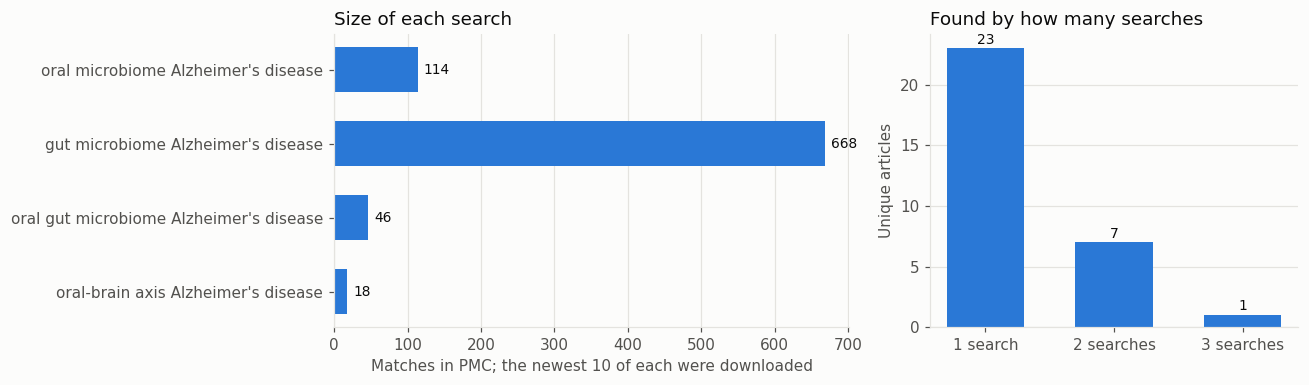

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})

bars = left.barh([tu.short(r["keyword"], 40) for r in runs][::-1], [r["found"] for r in runs][::-1],
                 color=tu.BLUE, height=0.6)
tu.bar_labels(left, bars, fmt="{:,.0f}", horizontal=True)
tu.gridlines(left, "x")
left.set_xlabel("Matches in PMC; the newest 10 of each were downloaded")
left.set_title("Size of each search")

overlap = corpus.searches.value_counts().sort_index()
bars = right.bar([f"{n} search{'es' if n > 1 else ''}" for n in overlap.index], overlap.values, color=tu.BLUE, width=0.6)
tu.bar_labels(right, bars)
tu.gridlines(right)
right.set_ylabel("Unique articles")
right.set_title("Found by how many searches")
plt.tight_layout()
plt.show()

## 4. Describe the corpus

A first look at when and where the corpus was published. PMC returns the newest matches first, so a small download is mostly recent work; raise `max_results`, or add a date range such as `AND 2015:2020[pdat]`, to reach further back.

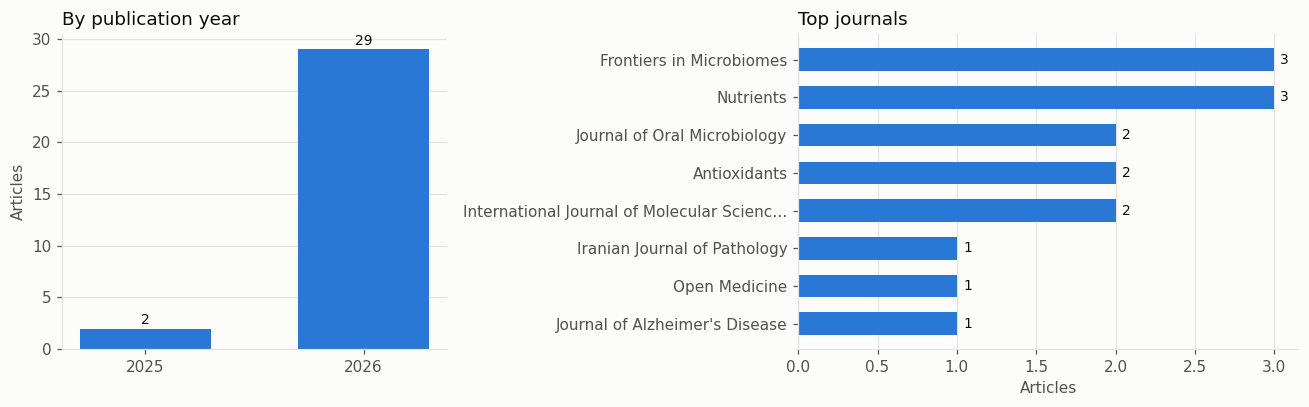

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})

years = corpus.year.value_counts().sort_index()
bars = left.bar([str(int(y)) for y in years.index], years.values, color=tu.BLUE, width=0.6)
tu.bar_labels(left, bars)
tu.gridlines(left)
left.set_ylabel("Articles")
left.set_title("By publication year")

journals = corpus.journal.value_counts().head(8)[::-1]
bars = right.barh([tu.short(j, 42) for j in journals.index], journals.values, color=tu.BLUE, height=0.6)
tu.bar_labels(right, bars, horizontal=True)
tu.gridlines(right, "x")
right.set_xlabel("Articles")
right.set_title("Top journals")
plt.tight_layout()
plt.show()

Screening starts with themes. Counting abstracts that mention each theme gives a quick map of the corpus and a way to pull out subsets, such as the animal studies or the articles about a specific bacterium.

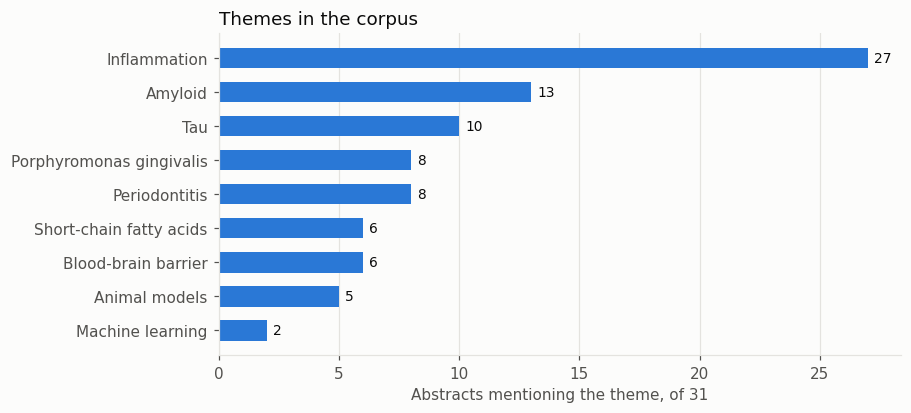

In [8]:
THEMES = {
    "Porphyromonas gingivalis": r"gingivalis",
    "Periodontitis": r"periodont",
    "Amyloid": r"amyloid",
    "Tau": r"\btau\b",
    "Inflammation": r"inflamm",
    "Short-chain fatty acids": r"short[- ]chain fatty|SCFA",
    "Blood-brain barrier": r"blood[- ]brain barrier",
    "Animal models": r"\bmice\b|\bmouse\b|\brats?\b",
    "Machine learning": r"machine learning|random forest|classifier",
}
for theme, pattern in THEMES.items():
    corpus[theme] = corpus.abstract.str.contains(pattern, case=False, regex=True)

counts = corpus[list(THEMES)].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(counts.index, counts.values, color=tu.BLUE, height=0.6)
tu.bar_labels(ax, bars, horizontal=True, zero=True)
tu.gridlines(ax, "x")
ax.set_xlabel(f"Abstracts mentioning the theme, of {len(corpus)}")
ax.set_title("Themes in the corpus")
plt.show()

In [9]:
# Example subset: articles about P. gingivalis, the bacterium behind gum disease
corpus.loc[corpus["Porphyromonas gingivalis"], ["year", "title", "journal"]].assign(
    title=lambda d: d.title.map(lambda t: tu.short(t, 80))
)

,year,title,journal
1,2026,A mechanistic framework linking the oral micro...,Journal of Alzheimer's Disease
3,2026,The Gut-Brain Axis in Neurodegeneration: Mecha...,Iranian Journal of Pathology
5,2026,From Mouth to Mind: Unraveling the Oral Microb...,Journal of Clinical Practice and Research
20,2026,Porphyromonas gingivalis induces intestinal in...,Microbiome
23,2026,The Interface of Oral and Brain Health: Curren...,CNS Neuroscience & Therapeutics
24,2025,"The role of the oral microbiome, host response...",Periodontology 2000
26,2026,Porphyromonas gingivalis disrupts hippocampal ...,Alzheimer's & Dementia
28,2026,The Oral-Brain Axis: Mechanistic Insights Link...,Cureus


## 5. Export the corpus

A CSV for spreadsheets and analysis, and a BibTeX file that Zotero, EndNote, Mendeley or LaTeX can import.

In [10]:
corpus.drop(columns=["abstract"]).assign(authors=corpus.authors.map("; ".join), found_by=corpus.found_by.map(" | ".join)) \
    .to_csv("review_corpus.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: Excel shows accents correctly

def bibtex(row):
    surname = re.sub(r"\W", "", (row.authors[0].split()[0] if row.authors else "anon"))
    first_word = re.sub(r"\W", "", row.title.split()[0]) if row.title else "untitled"
    fields = {
        "title": row.title, "author": " and ".join(row.authors), "journal": row.journal,
        "year": row.year, "doi": row.doi, "pmid": row.pmid, "pmcid": row.pmcid,
        "url": f"https://pmc.ncbi.nlm.nih.gov/articles/{row.pmcid}/",
    }
    body = ",\n".join(f"  {k} = {{{v}}}" for k, v in fields.items() if v)
    return f"@article{{{surname}{row.year}{first_word},\n{body}\n}}"

entries = [bibtex(row) for row in corpus.itertuples()]
Path("review_corpus.bib").write_text("\n\n".join(entries) + "\n", encoding="utf-8")
print(f"Wrote review_corpus.csv and review_corpus.bib ({len(entries)} entries). The first entry:\n")
print(entries[0])

Wrote review_corpus.csv and review_corpus.bib (31 entries). The first entry:

@article{Zhao2026Fecal,
  title = {Fecal microbiota transplantation: from empirical remedy to precision medicine},
  author = {Zhao Junsheng and Fan Yiming and Yang Keda and Gao Hainv},
  journal = {Frontiers in Microbiomes},
  year = {2026},
  doi = {10.3389/frmbi.2026.1863308},
  pmid = {42388392},
  pmcid = {PMC13318992},
  url = {https://pmc.ncbi.nlm.nih.gov/articles/PMC13318992/}
}


## 6. Turn the corpus into a knowledge graph

The download folders can go straight into a knowledge graph, which links the articles by citation and by MeSH topic. Tutorial 5 explores such a graph in depth.

In [11]:
result = create_kg(KG_TOPIC, sources=[r["folder"] for r in runs])
print(result.vault)


Obsidian vault
Vault:             workspace\kg_oral_gut_microbiome_alzheimer
Sources:           4
Papers:            31 (31 full text, 0 stubs)
MeSH concepts:     48
Collections:       4
Notes:             84 created, 0 updated, 0 unchanged
PubMed records:    28 fetched
  - Without MeSH:  17 (offline, too new, or a journal outside MEDLINE)
